In [4]:
# model polega na przesadzie ze najblizsze otoczenie w jakis sposob nas definiuje
import numpy as np
from typing import List
from collections import Counter
from typing import NamedTuple

def raw_majority_vote(labels: List[str]) -> str:
    "zwraca najczesniej pojawiajacy sie label w labels"
    votes = Counter(labels)
    winner, _ = votes.most_common(1)[0]
    return winner

assert raw_majority_vote(['a','b','c','b']) == 'b'

# co jak bedzie kilka tak samo liczbych labeli?
# np. usuwamy najdalszego siasiada (wedle konwensji ostatni elemnt listy)

def majority_vote(labels: List[str]) -> str:
    votes = Counter(labels)
    winner, winner_count = votes.most_common(1)[0]
    num_winers = len([count 
                      for count in votes.values() 
                      if count == winner_count])
    if num_winers == 1:
        return winner
    else:
        return majority_vote(labels[:-1])

assert raw_majority_vote(['a','b','c','b','c']) == 'b' # 2 razy b i c ale po usunieciu ostatniego c b bedzie wiecej

In [30]:
import requests
import csv
from typing import Dict
from collections import defaultdict
# funkcja do labelowania nowych danych na podstawie ich najblizszych sasiadow 
class labeled_point(NamedTuple):
    point: List[float]
    label: str

def knn_classify(k: int, labeled_points: List[labeled_point], new_point: List[float]) -> str:
    'na podstawie k najblizszych sasiadow ustaw label dla nowego wektora'
    sort_by_distance = sorted(
        labeled_points, 
        key=lambda lp: np.linalg.norm(np.array(lp.point) - np.array(new_point)))
    
    k_nearest_labels = [lp.label for lp in sort_by_distance[:k]]

    return majority_vote(k_nearest_labels)
# przetestujmy to na realnych danych 

data = requests.get('https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data')
with open('iris.dat', 'w') as f: # zapisujemy do oddzielnego pliku txt
    f.write(data.text)

def parse_iris_row(row: List[str]) -> labeled_point:
    "sepal_lenght, sepal_width, petal_lenght, petal_width, class"
    measurements = [float(val) for val in row[:-1]] # bez clasy
    label = row[-1].split("-")[-1]
    return labeled_point(measurements, label)

with open('/Users/ignacyboczula/Desktop/Data_science_Joel_Grus/chapter_12/iris.dat') as f:
    reader = csv.reader(f)
    iris_data = [parse_iris_row(row) for row in reader if row]

print(iris_data[:2])
print(Counter([lab.label for lab in iris_data]))

[labeled_point(point=[5.1, 3.5, 1.4, 0.2], label='setosa'), labeled_point(point=[4.9, 3.0, 1.4, 0.2], label='setosa')]
Counter({'setosa': 50, 'versicolor': 50, 'virginica': 50})


In [26]:
import matplotlib.pyplot as plt
# przedstawmy te dane na wykresie 
points_by_species: Dict[str, List[List[float]]] = defaultdict(list)
for iris in iris_data:
    points_by_species[iris.label].append(iris.point)
metrics = ['sepal_lenght', 'sepal_width', 'petal_lenght', 'petal_width', 'class']
# w iris_data sa trzy klasy
pairs = [(i,j) for i in range(4) for j in range(4) if i<j] 
marks = ['+', '.', 'x']

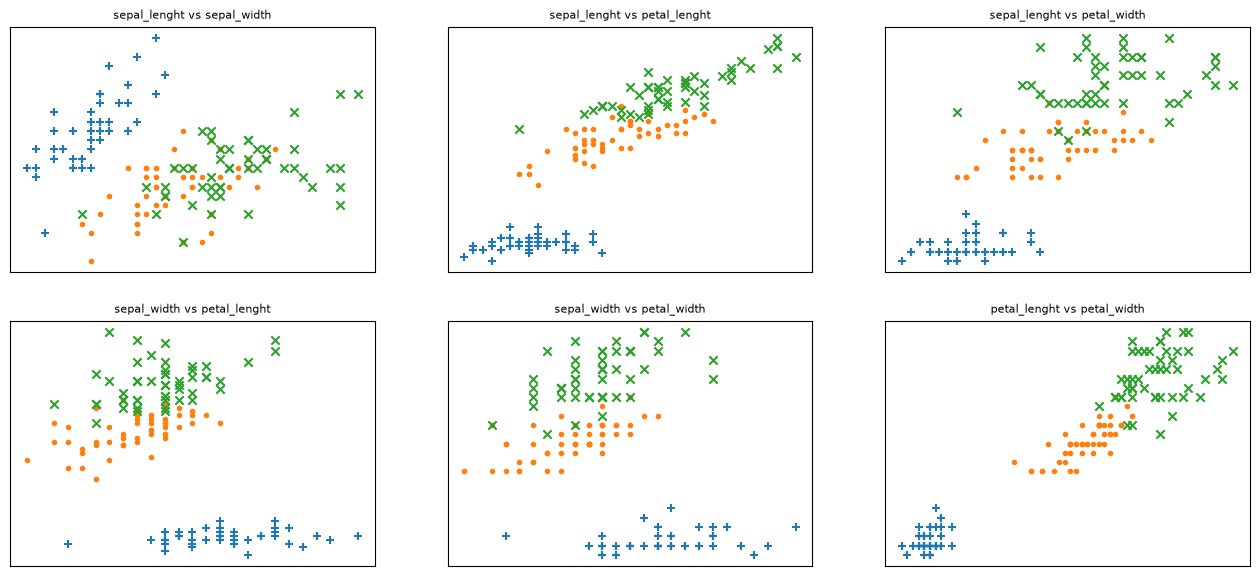

In [28]:
fix, ax = plt.subplots(2,3, figsize=(16,7))
for row in range(2):
    for col in range(3):
        i, j = pairs[3 * row + col]
        ax[row][col].set_title(f'{metrics[i]} vs {metrics[j]}', fontsize = 8)
        ax[row][col].set_xticks([])
        ax[row][col].set_yticks([])

        for mark, (species, points) in zip(marks, points_by_species.items()):
            xs = [p[i] for p in points]
            ys = [p[j] for p in points]
            ax[row][col].scatter(xs,ys, marker = mark, label = species)
plt.show()

In [36]:
# przetestujmy masz model
import random
from typing import TypeVar, List, Tuple

X = TypeVar('X')
def split_data(data: List[X], prob: float) -> Tuple[List[X], List[X]]:
    'dzieli dane na dwie czesci (prob, 1-prob)'
    data = data[:]
    random.shuffle(data)
    cut = int(len(data) * prob)
    return data[:cut], data[cut:]
random.seed(67)

iris_train, iris_test = split_data(iris_data, 0.70)
from typing import Tuple

confusion_matrix : Dict[Tuple[str, str], int] = defaultdict(int)

num_correct = 0
for iris in iris_test:
    pred = knn_classify(5, iris_train, iris.point)
    actual = iris.label
    if pred == actual:
        num_correct += 1
    confusion_matrix[(pred, actual)] += 1

acc = num_correct / len(iris_test)
print(acc, confusion_matrix)

0.9555555555555556 defaultdict(<class 'int'>, {('virginica', 'virginica'): 14, ('versicolor', 'versicolor'): 16, ('setosa', 'setosa'): 13, ('virginica', 'versicolor'): 1, ('versicolor', 'virginica'): 1})
